# 01: Main experiments

Sweep-grouped chronological split, ten-seed headline model and ablations A1 to A4 (Table 6), test-set λ sweep (Section 4.3), physics-penalty activation counts (Section 2.3.2), empirical |Z| and R_ct-proxy vs. SoC (Figures 8A and 8B), spectrum-level aggregation (Section 4.7), and five-seed leave-one-cell-out validation (superseded by the ten-seed version in notebook 04).

**Run:** place `impedance.csv` and `frequencies.csv` in `data/` (or upload them when prompted in Colab), then Runtime → Run all. Saved outputs are those reported in the manuscript.

## 0. Setup

In [ ]:

import sys, subprocess
# Colab usually has these; this is a harmless no-op if already satisfied.
for pkg in ["torch", "scikit-learn", "scipy", "pandas", "numpy", "matplotlib"]:
    pass  # Colab ships all of these by default; left here as a reminder if running elsewhere.

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report, precision_score, recall_score)
from scipy import stats
import matplotlib.pyplot as plt
import random, json, time, os

t0 = time.time()
print("Setup OK.")


Setup OK.


In [ ]:

# --- Upload data (Colab) ---------------------------------------------------
# If running in Colab and the files aren't already present, this will prompt
# an upload dialog. If running locally with data/impedance.csv and
# data/frequencies.csv already in place, this cell is skipped automatically.
import os

IMP_PATH, FREQ_PATH = "data/impedance.csv", "data/frequencies.csv"

if not (os.path.exists(IMP_PATH) and os.path.exists(FREQ_PATH)):
    os.makedirs("data", exist_ok=True)
    try:
        from google.colab import files
        print("Please upload impedance.csv and frequencies.csv:")
        uploaded = files.upload()
        for fname in uploaded:
            target = "data/" + fname
            with open(target, "wb") as f:
                f.write(uploaded[fname])
            print("saved", target)
    except ImportError:
        raise FileNotFoundError(
            "data/impedance.csv and data/frequencies.csv not found, and this "
            "doesn't look like Colab. Place both files under a data/ folder "
            "next to this notebook and re-run this cell."
        )

assert os.path.exists(IMP_PATH) and os.path.exists(FREQ_PATH), "Data files still missing."
print("Data files present.")


Please upload impedance.csv and frequencies.csv:


Saving frequencies (2).csv to frequencies (2).csv
Saving impedance (2).csv to impedance (2).csv
saved data/frequencies (2).csv
saved data/impedance (2).csv
Data files present.


## 1. Shared preprocessing (same feature engineering as the manuscript, unchanged)

In [ ]:

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cpu")

impedance = pd.read_csv(IMP_PATH)
frequencies = pd.read_csv(FREQ_PATH)
df = impedance.merge(frequencies, on="FREQUENCY_ID", how="left")
df["SWEEP_ID"] = (df["BATTERY_ID"].astype(str) + "_" + df["MEASURE_ID"].astype(str) + "_" + df["SOC"].astype(str))
GROUP_COL = "SWEEP_ID"

def parse_complex(s):
    if pd.isna(s): return np.nan
    s = str(s).replace(" ", "").replace("(", "").replace(")", "")
    try: return complex(s)
    except ValueError: return np.nan

df["Z_complex"] = df["IMPEDANCE_VALUE"].apply(parse_complex)
df["Re_Z"] = df["Z_complex"].apply(lambda z: z.real)
df["Im_Z"] = df["Z_complex"].apply(lambda z: z.imag)
df["abs_Z"] = df["Z_complex"].apply(lambda z: abs(z))
df = df.dropna(subset=["Re_Z", "Im_Z", "abs_Z", "SOC"]).reset_index(drop=True)
freq_col = "FREQUENCY_VALUE"
df["log10_f"] = np.log10(df[freq_col].astype(float))
df["phi"] = np.arctan2(df["Im_Z"], df["Re_Z"])
SOC_THRESHOLD = 60
df["label"] = (df["SOC"] >= SOC_THRESHOLD).astype(int)
FEATS = ["log10_f", "Re_Z", "Im_Z", "abs_Z", "phi"]

print(f"Loaded {len(df)} raw frequency measurements across "
      f"{df['BATTERY_ID'].nunique()} batteries and {df['SWEEP_ID'].nunique()} distinct EIS sweeps.")
print("Batteries:", sorted(df['BATTERY_ID'].unique().tolist()))


Loaded 3360 raw frequency measurements across 4 batteries and 240 distinct EIS sweeps.
Batteries: [2, 3, 5, 6]


In [ ]:

def make_windows(group, drop_phase=False, window=True):
    g = group.sort_values(freq_col).reset_index(drop=True)
    feats = FEATS if not drop_phase else ["log10_f", "Re_Z", "Im_Z", "abs_Z"]
    rows, labels, zcentre = [], [], []
    n = len(g)
    if window:
        for i in range(1, n - 1):
            vec = np.concatenate([g.loc[i-1, feats].values, g.loc[i, feats].values, g.loc[i+1, feats].values]).astype(float)
            rows.append(vec); labels.append(g.loc[i, "label"]); zcentre.append(g.loc[i, "abs_Z"])
    else:
        for i in range(n):
            vec = g.loc[i, feats].values.astype(float)
            rows.append(vec); labels.append(g.loc[i, "label"]); zcentre.append(g.loc[i, "abs_Z"])
    return rows, labels, zcentre

def build_dataset(drop_phase=False, window=True, battery_filter=None):
    # Returns X, y, z, sweep_ids, battery_ids (metadata carried per-window
    # so later steps can aggregate by sweep or hold out a battery, instead of
    # re-parsing SWEEP_ID strings).
    X, y, z, sweep_ids, battery_ids = [], [], [], [], []
    for key, g in df.groupby(GROUP_COL, sort=False):
        bat = str(g["BATTERY_ID"].iloc[0])
        if battery_filter is not None and bat not in battery_filter:
            continue
        rows, labels, zc = make_windows(g, drop_phase=drop_phase, window=window)
        X.extend(rows); y.extend(labels); z.extend(zc)
        sweep_ids.extend([key] * len(rows))
        battery_ids.extend([bat] * len(rows))
    return np.array(X), np.array(y), np.array(z), np.array(sweep_ids), np.array(battery_ids)

X_full, y_full, z_full, sweep_full, battery_full = build_dataset(drop_phase=False, window=True)
print(f"Full windowed dataset: n={len(X_full)} (expected 2,880 per the corrected preprocessing).")


Full windowed dataset: n=2880 (expected 2,880 per the corrected preprocessing).



## 2. The split-boundary fix

The existing pipeline builds the full window array by iterating sweeps in
order and concatenating, so each sweep's windows *are* contiguous in the
array — but the old `chrono_split` then cut at `round(0.70*n)` /
`round(0.85*n)` by raw index, which can land in the middle of a sweep's
block and split a handful of its windows across adjacent partitions.

The fix below finds the sweep boundary closest to each target cut point and
snaps to it, so **no sweep is ever split across train/val/test**. This is
the grouped-splitting fix at the row level; it's
cheaper than full leave-one-cell-out (Section 6 below) and should be applied
regardless of whether LOCO is also reported.


In [ ]:

def group_boundary_indices(sweep_ids):
    # Cumulative length of each contiguous sweep block, in order of first
    # appearance (matches how build_dataset concatenates them).
    boundaries = [0]
    prev = sweep_ids[0]
    for i in range(1, len(sweep_ids)):
        if sweep_ids[i] != prev:
            boundaries.append(i)
            prev = sweep_ids[i]
    boundaries.append(len(sweep_ids))
    return boundaries

def grouped_chrono_split(X, y, z, sweep_ids):
    n = len(X)
    target_train, target_val = 0.70 * n, 0.85 * n
    boundaries = group_boundary_indices(sweep_ids)
    n_train = min(boundaries, key=lambda b: abs(b - target_train))
    # choose the val cut from boundaries strictly after n_train
    later = [b for b in boundaries if b > n_train]
    n_trainval = min(later, key=lambda b: abs(b - target_val))
    assert n_train < n_trainval <= n
    # sanity: confirm no sweep straddles a cut
    for cut in (n_train, n_trainval):
        if cut < n:
            assert sweep_ids[cut - 1] != sweep_ids[cut], f"cut at {cut} splits a sweep!"
    return (X[:n_train], y[:n_train], z[:n_train],
            X[n_train:n_trainval], y[n_train:n_trainval], z[n_train:n_trainval],
            X[n_trainval:], y[n_trainval:], z[n_trainval:],
            n_train, n_trainval)

(X_tr, y_tr, z_tr, X_val, y_val, z_val, X_te, y_te, z_te,
 cut_train, cut_trainval) = grouped_chrono_split(X_full, y_full, z_full, sweep_full)

print(f"Corrected split (sweep-boundary-respecting): "
      f"train={len(X_tr)}, val={len(X_val)}, test={len(X_te)}  "
      f"(old split target was 2016/432/432; compare below)")
print(f"Cut points: {cut_train}, {cut_trainval} out of {len(X_full)}")

# Also carry sweep/battery metadata through the same split for later sections.
sweep_tr, sweep_val, sweep_te = sweep_full[:cut_train], sweep_full[cut_train:cut_trainval], sweep_full[cut_trainval:]
battery_tr, battery_val, battery_te = battery_full[:cut_train], battery_full[cut_train:cut_trainval], battery_full[cut_trainval:]


Corrected split (sweep-boundary-respecting): train=2016, val=432, test=432  (old split target was 2016/432/432; compare below)
Cut points: 2016, 2448 out of 2880


In [ ]:

def normalise_z(z_train, *others):
    zmin, zmax = z_train.min(), z_train.max()
    def norm(z): return np.clip((z - zmin) / (zmax - zmin + 1e-12), 0, 1)
    return (norm(z_train),) + tuple(norm(o) for o in others)

scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_val), scaler.transform(X_te)
z_tr_n, z_val_n, z_te_n = normalise_z(z_tr, z_val, z_te)
print("Scaler fit on the corrected training split only (no leakage).")


Scaler fit on the corrected training split only (no leakage).


## 3. Model definition and training loop (unchanged architecture/hyperparameters)

In [ ]:

class PGNN(nn.Module):
    def __init__(self, in_dim=15):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim,128), nn.Tanh(), nn.Dropout(0.2),
            nn.Linear(128,128), nn.Tanh(), nn.Dropout(0.2), nn.Linear(128,64), nn.Tanh(), nn.Linear(64,2))
    def forward(self, x): return self.net(x)

def physics_loss(p1, z_norm):
    mask = (z_norm > 0.5).float()
    return torch.mean(p1 * z_norm * mask)

def train_pgnn(X_train, y_train, z_train, X_val, y_val, lam=1.0, in_dim=15,
               lr=5e-4, max_epochs=300, patience=25, batch_size=64, seed=42):
    torch.manual_seed(seed)
    Xt = torch.tensor(X_train, dtype=torch.float32); yt = torch.tensor(y_train, dtype=torch.long)
    zt = torch.tensor(z_train, dtype=torch.float32)
    Xv = torch.tensor(X_val, dtype=torch.float32); yv = torch.tensor(y_val, dtype=torch.long)
    model = PGNN(in_dim)
    ce = nn.CrossEntropyLoss()
    opt = optim.Adam(model.parameters(), lr=lr, betas=(0.9,0.999), weight_decay=1e-4)
    sched = optim.lr_scheduler.StepLR(opt, step_size=50, gamma=0.5)
    n = len(Xt); best_val_loss, best_state, bad_epochs = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]; xb, yb, zb = Xt[idx], yt[idx], zt[idx]
            opt.zero_grad(); logits = model(xb); probs = torch.softmax(logits, dim=1)
            loss = ce(logits, yb) + lam * physics_loss(probs[:,1], zb)
            loss.backward(); opt.step()
        sched.step()
        model.eval()
        with torch.no_grad():
            val_loss = ce(model(Xv), yv).item()
        if val_loss < best_val_loss - 1e-6:
            best_val_loss, best_state, bad_epochs = val_loss, {k:v.clone() for k,v in model.state_dict().items()}, 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience: break
    model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict_proba(model, X):
    model.eval(); Xt = torch.tensor(X, dtype=torch.float32)
    return torch.softmax(model(Xt), dim=1)[:,1].numpy()

def youden_threshold(y_true, p1):
    fpr, tpr, thr = roc_curve(y_true, p1); j = tpr - fpr
    return thr[np.argmax(j)]

def evaluate(y_true, p1, tau):
    y_pred = (p1 >= tau).astype(int)
    return {"accuracy": accuracy_score(y_true,y_pred), "macro_f1": f1_score(y_true,y_pred,average="macro"),
            "auc": roc_auc_score(y_true,p1), "threshold": float(tau)}

print("Model/training utilities defined.")


Model/training utilities defined.



## 4. Experiment 1 — headline model + ablation (A1–A4) on the corrected split

Same four ablation variants as the manuscript (A1: no sliding window, A2: no
phase feature, A3: default threshold 0.5 instead of Youden, A4: no physics
loss), each run across `N_SEEDS_MAIN` seeds on the **corrected,
sweep-boundary-respecting split**. Paired t-test against the full model,
same as before.

Lower `N_SEEDS_MAIN` if you need this to run faster; 10 matches what's
already in the manuscript for comparability.


In [ ]:

N_SEEDS_MAIN = 10
SEEDS_MAIN = list(range(N_SEEDS_MAIN))

def run_variant(variant, seed, lam=1.0, fixed_threshold=None, drop_phase=False, window=True):
    if window == X_tr.shape[1] == 15 and drop_phase == False and True:
        pass  # placeholder to keep branches explicit below
    if drop_phase or not window:
        Xf, yf, zf, sf, bf = build_dataset(drop_phase=drop_phase, window=window)
        (Xtr_, ytr_, ztr_, Xv_, yv_, zv_, Xte_, yte_, zte_, _, _) = grouped_chrono_split(Xf, yf, zf, sf)
        sc = StandardScaler().fit(Xtr_)
        Xtr_s, Xv_s, Xte_s = sc.transform(Xtr_), sc.transform(Xv_), sc.transform(Xte_)
        ztr_n, zv_n, zte_n = normalise_z(ztr_, zv_, zte_)
        in_dim = Xtr_s.shape[1]
    else:
        Xtr_s, yf_tr, ztr_n = X_tr_s, y_tr, z_tr_n
        Xv_s, yf_val, zv_n = X_val_s, y_val, z_val_n
        Xte_s, yf_te, zte_n = X_te_s, y_te, z_te_n
        in_dim = X_tr_s.shape[1]
        ytr_, yv_, yte_ = y_tr, y_val, y_te

    model = train_pgnn(Xtr_s, ytr_, ztr_n, Xv_s, yv_, lam=lam, in_dim=in_dim, seed=seed)
    p1_val = predict_proba(model, Xv_s)
    p1_te = predict_proba(model, Xte_s)
    tau = fixed_threshold if fixed_threshold is not None else youden_threshold(yv_, p1_val)
    return evaluate(yte_, p1_te, tau)

results = {"full": [], "A1_no_window": [], "A2_no_phase": [], "A3_default_threshold": [], "A4_no_physics": []}
t1 = time.time()
for seed in SEEDS_MAIN:
    results["full"].append(run_variant("full", seed, lam=1.0))
    results["A1_no_window"].append(run_variant("A1", seed, lam=1.0, window=False))
    results["A2_no_phase"].append(run_variant("A2", seed, lam=1.0, drop_phase=True))
    results["A3_default_threshold"].append(run_variant("A3", seed, lam=1.0, fixed_threshold=0.5))
    results["A4_no_physics"].append(run_variant("A4", seed, lam=0.0))
    print(f"seed {seed} done ({time.time()-t1:.0f}s elapsed)")

summary = {}
full_f1 = np.array([r["macro_f1"] for r in results["full"]])
full_acc = np.array([r["accuracy"] for r in results["full"]])
for k, rs in results.items():
    f1s = np.array([r["macro_f1"] for r in rs]); accs = np.array([r["accuracy"] for r in rs])
    entry = {"mean_macro_f1": float(f1s.mean()), "sd_macro_f1": float(f1s.std()),
             "mean_accuracy": float(accs.mean()), "sd_accuracy": float(accs.std())}
    if k != "full":
        tstat, pval = stats.ttest_rel(f1s, full_f1)
        entry["delta_f1_vs_full"] = float(f1s.mean() - full_f1.mean())
        entry["p_value_vs_full"] = float(pval)
    summary[k] = entry
    print(k, entry)

with open("corrected_split_ablation.json", "w") as f:
    json.dump({"n_seeds": N_SEEDS_MAIN, "split_sizes": {"train": len(X_tr), "val": len(X_val), "test": len(X_te)},
               "summary": summary}, f, indent=2)
print("Saved corrected_split_ablation.json")


seed 0 done (37s elapsed)
seed 1 done (80s elapsed)
seed 2 done (120s elapsed)
seed 3 done (168s elapsed)
seed 4 done (216s elapsed)
seed 5 done (262s elapsed)
seed 6 done (303s elapsed)
seed 7 done (343s elapsed)
seed 8 done (394s elapsed)
seed 9 done (445s elapsed)
full {'mean_macro_f1': 0.7972127872760082, 'sd_macro_f1': 0.03677429906029007, 'mean_accuracy': 0.8043981481481481, 'sd_accuracy': 0.033001336642090866}
A1_no_window {'mean_macro_f1': 0.8057413170649006, 'sd_macro_f1': 0.02108917315241557, 'mean_accuracy': 0.8140873015873016, 'sd_accuracy': 0.020370907194190845, 'delta_f1_vs_full': 0.008528529788892403, 'p_value_vs_full': 0.5906645242857156}
A2_no_phase {'mean_macro_f1': 0.7976603585445643, 'sd_macro_f1': 0.02971416961588439, 'mean_accuracy': 0.806712962962963, 'sd_accuracy': 0.026580082234728644, 'delta_f1_vs_full': 0.00044757126855610174, 'p_value_vs_full': 0.9752841859011654}
A3_default_threshold {'mean_macro_f1': 0.7112685392146751, 'sd_macro_f1': 0.06747734371684663, 


## 5. Experiment 1b — λ sweep on the corrected split

Same grid as the manuscript (0 to 5.0), `N_SEEDS_LAMBDA` seeds each, paired
t-test against λ=0.


In [ ]:

N_SEEDS_LAMBDA = 8
LAMBDA_GRID = [0.0, 0.01, 0.05, 0.10, 0.50, 1.0, 2.0, 5.0]

lambda_results = {lam: [] for lam in LAMBDA_GRID}
t2 = time.time()
for seed in range(N_SEEDS_LAMBDA):
    for lam in LAMBDA_GRID:
        model = train_pgnn(X_tr_s, y_tr, z_tr_n, X_val_s, y_val, lam=lam, seed=seed)
        p1_val = predict_proba(model, X_val_s)
        tau = youden_threshold(y_val, p1_val)
        p1_te = predict_proba(model, X_te_s)
        lambda_results[lam].append(evaluate(y_te, p1_te, tau))
    print(f"seed {seed} done ({time.time()-t2:.0f}s elapsed)")

lam0_f1 = np.array([r["macro_f1"] for r in lambda_results[0.0]])
lambda_summary = {}
for lam, rs in lambda_results.items():
    f1s = np.array([r["macro_f1"] for r in rs])
    entry = {"mean_macro_f1": float(f1s.mean()), "sd_macro_f1": float(f1s.std())}
    if lam != 0.0:
        _, pval = stats.ttest_rel(f1s, lam0_f1)
        entry["delta_f1_vs_lambda0"] = float(f1s.mean() - lam0_f1.mean())
        entry["p_value_vs_lambda0"] = float(pval)
    lambda_summary[lam] = entry
    print(lam, entry)

with open("corrected_lambda_sweep.json", "w") as f:
    json.dump({"n_seeds": N_SEEDS_LAMBDA, "summary": {str(k): v for k, v in lambda_summary.items()}}, f, indent=2)
print("Saved corrected_lambda_sweep.json")


seed 0 done (22s elapsed)
seed 1 done (77s elapsed)
seed 2 done (133s elapsed)
seed 3 done (208s elapsed)
seed 4 done (274s elapsed)
seed 5 done (340s elapsed)
seed 6 done (397s elapsed)
seed 7 done (469s elapsed)
0.0 {'mean_macro_f1': 0.7663043422956559, 'sd_macro_f1': 0.03025701342021331}
0.01 {'mean_macro_f1': 0.7634937892969356, 'sd_macro_f1': 0.029361470620757, 'delta_f1_vs_lambda0': -0.0028105529987203504, 'p_value_vs_lambda0': 0.15904309879750908}
0.05 {'mean_macro_f1': 0.7671251033567252, 'sd_macro_f1': 0.025222729701571488, 'delta_f1_vs_lambda0': 0.0008207610610693195, 'p_value_vs_lambda0': 0.7310116133189364}
0.1 {'mean_macro_f1': 0.7588353367114544, 'sd_macro_f1': 0.030606309903728143, 'delta_f1_vs_lambda0': -0.0074690055842014935, 'p_value_vs_lambda0': 0.41799991739800957}
0.5 {'mean_macro_f1': 0.7800787193568243, 'sd_macro_f1': 0.029786738716508727, 'delta_f1_vs_lambda0': 0.013774377061168352, 'p_value_vs_lambda0': 0.07555277584393004}
1.0 {'mean_macro_f1': 0.7930828506352


## 6. Experiment 2 — physics-penalty activation counts

Direct count of how many samples have `z_norm > 0.5` (i.e., actually get
penalized), broken down by split and true class. No retraining needed — this
uses the z-normalization already fit on the training split.


In [ ]:

def activation_counts(z_norm, y):
    mask = z_norm > 0.5
    out = {"n_total": int(len(y)), "n_activated": int(mask.sum()),
           "pct_activated": float(mask.mean() * 100)}
    for cls, name in [(0, "Low-Mid_SoC"), (1, "High_SoC")]:
        sub = mask[y == cls]
        out[f"n_activated_{name}"] = int(sub.sum())
        out[f"pct_activated_{name}"] = float(sub.mean() * 100) if len(sub) else float("nan")
    return out

penalty_counts = {
    "train": activation_counts(z_tr_n, y_tr),
    "val": activation_counts(z_val_n, y_val),
    "test": activation_counts(z_te_n, y_te),
}
for split, counts in penalty_counts.items():
    print(split, counts)

with open("physics_penalty_activation.json", "w") as f:
    json.dump(penalty_counts, f, indent=2)
print("Saved physics_penalty_activation.json")


train {'n_total': 2016, 'n_activated': 756, 'pct_activated': 37.5, 'n_activated_Low-Mid_SoC': 418, 'pct_activated_Low-Mid_SoC': 41.967871485943775, 'n_activated_High_SoC': 338, 'pct_activated_High_SoC': 33.13725490196078}
val {'n_total': 432, 'n_activated': 205, 'pct_activated': 47.4537037037037, 'n_activated_Low-Mid_SoC': 108, 'pct_activated_Low-Mid_SoC': 52.94117647058824, 'n_activated_High_SoC': 97, 'pct_activated_High_SoC': 42.54385964912281}
test {'n_total': 432, 'n_activated': 227, 'pct_activated': 52.54629629629629, 'n_activated_Low-Mid_SoC': 140, 'pct_activated_Low-Mid_SoC': 58.333333333333336, 'n_activated_High_SoC': 87, 'pct_activated_High_SoC': 45.3125}
Saved physics_penalty_activation.json



## 7. Experiment 3 — empirical |Z| vs. SoC per frequency, and a simple Rct proxy

Two things here:

- **|Z| vs. SoC at each measured frequency**, averaged over repeat sweeps and
  batteries — the direct empirical basis for "impedance magnitude relates
  monotonically to SoC" that the physics loss assumes.
- **A simple Rct proxy**: for a classic Randles circuit, the real-axis span
  of the semicircle (Re(Z) at the lowest frequency minus Re(Z) at the
  highest frequency) approximates Rct. This is a standard back-of-envelope
  estimate, **not a nonlinear equivalent-circuit fit** — the notebook says so
  in the output, and the manuscript text should say so too rather than
  calling it a fitted Rct.


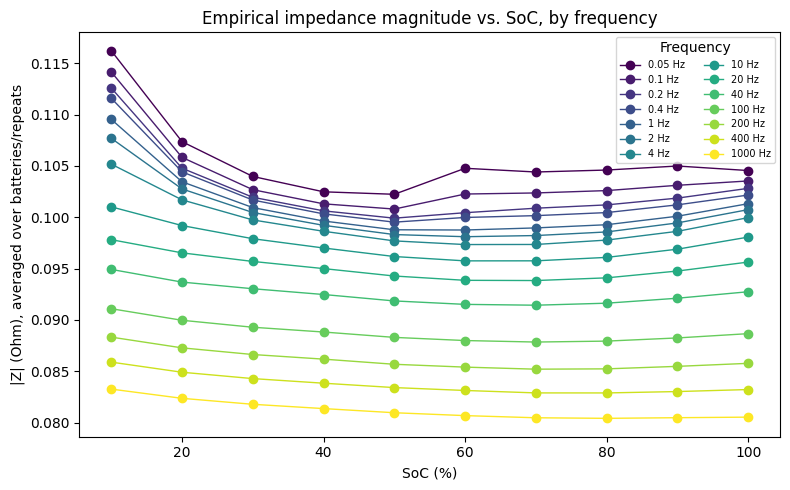

Saved impedance_magnitude_vs_soc.png


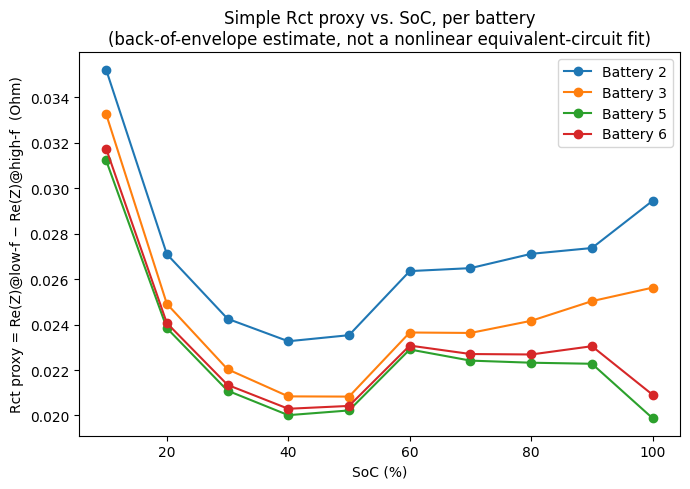

Saved rct_proxy_vs_soc.png
Saved rct_proxy_table.csv and impedance_magnitude_vs_soc_table.csv
BATTERY_ID
2    [{'SOC': 10, 'Rct_proxy': 0.03520837578069218}...
3    [{'SOC': 10, 'Rct_proxy': 0.03325563885323139}...
5    [{'SOC': 10, 'Rct_proxy': 0.031219510749859528...
6    [{'SOC': 10, 'Rct_proxy': 0.03173671995620882}...
dtype: object


/tmp/ipykernel_1066/1915652647.py:45: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(rct_df.groupby('BATTERY_ID').apply(lambda g: g.sort_values('SOC')[['SOC','Rct_proxy']].to_dict('records')))


In [ ]:

freq_vals = sorted(df["FREQUENCY_VALUE"].unique())
soc_vals = sorted(df["SOC"].unique())

# |Z| vs SoC per frequency, averaged across batteries and repeat measurements
pivot_absZ = df.groupby(["FREQUENCY_VALUE", "SOC"])["abs_Z"].mean().reset_index()

plt.figure(figsize=(8,5))
cmap = plt.cm.viridis(np.linspace(0, 1, len(freq_vals)))
for fval, c in zip(freq_vals, cmap):
    sub = pivot_absZ[pivot_absZ["FREQUENCY_VALUE"] == fval].sort_values("SOC")
    plt.plot(sub["SOC"], sub["abs_Z"], marker="o", color=c, label=f"{fval:g} Hz", linewidth=1)
plt.xlabel("SoC (%)"); plt.ylabel("|Z| (Ohm), averaged over batteries/repeats")
plt.title("Empirical impedance magnitude vs. SoC, by frequency")
plt.legend(fontsize=7, ncol=2, title="Frequency")
plt.tight_layout()
plt.savefig("impedance_magnitude_vs_soc.png", dpi=200)
plt.show()
print("Saved impedance_magnitude_vs_soc.png")

# Simple Rct proxy: Re(Z) at lowest freq minus Re(Z) at highest freq, per battery/SoC
lo_f, hi_f = min(freq_vals), max(freq_vals)
rct_rows = []
for (bat, soc), g in df.groupby(["BATTERY_ID", "SOC"]):
    re_lo = g.loc[g["FREQUENCY_VALUE"] == lo_f, "Re_Z"].mean()
    re_hi = g.loc[g["FREQUENCY_VALUE"] == hi_f, "Re_Z"].mean()
    if pd.notna(re_lo) and pd.notna(re_hi):
        rct_rows.append({"BATTERY_ID": bat, "SOC": soc, "Rct_proxy": re_lo - re_hi})
rct_df = pd.DataFrame(rct_rows)

plt.figure(figsize=(7,5))
for bat, g in rct_df.groupby("BATTERY_ID"):
    g = g.sort_values("SOC")
    plt.plot(g["SOC"], g["Rct_proxy"], marker="o", label=f"Battery {bat}")
plt.xlabel("SoC (%)"); plt.ylabel("Rct proxy = Re(Z)@low-f − Re(Z)@high-f  (Ohm)")
plt.title("Simple Rct proxy vs. SoC, per battery\n(back-of-envelope estimate, not a nonlinear equivalent-circuit fit)")
plt.legend()
plt.tight_layout()
plt.savefig("rct_proxy_vs_soc.png", dpi=200)
plt.show()
print("Saved rct_proxy_vs_soc.png")

rct_df.to_csv("rct_proxy_table.csv", index=False)
pivot_absZ.to_csv("impedance_magnitude_vs_soc_table.csv", index=False)
print("Saved rct_proxy_table.csv and impedance_magnitude_vs_soc_table.csv")
print(rct_df.groupby('BATTERY_ID').apply(lambda g: g.sort_values('SOC')[['SOC','Rct_proxy']].to_dict('records')))



## 8. Experiment 4 — spectrum-level aggregated evaluation

Instead of scoring every overlapping window independently, aggregate the
full model's test-set window predictions back up to **one decision per EIS
sweep** (majority vote across that sweep's windows, using the same frozen
Youden threshold), and report accuracy/macro-F1 at that level. This is the
practically meaningful unit for an actual BMS decision.


In [ ]:

# Use the full model trained in Experiment 1 at seed=42 (reproducible default) for this illustration.
model_full = train_pgnn(X_tr_s, y_tr, z_tr_n, X_val_s, y_val, lam=1.0, seed=42)
p1_val_full = predict_proba(model_full, X_val_s)
tau_full = youden_threshold(y_val, p1_val_full)
p1_te_full = predict_proba(model_full, X_te_s)
y_pred_window = (p1_te_full >= tau_full).astype(int)

window_level = evaluate(y_te, p1_te_full, tau_full)

spectrum_df = pd.DataFrame({"sweep_id": sweep_te, "y_true": y_te, "y_pred": y_pred_window, "p1": p1_te_full})
agg = spectrum_df.groupby("sweep_id").agg(
    y_true=("y_true", "first"),  # label is constant within a sweep
    y_pred_majority=("y_pred", lambda s: int(s.mean() >= 0.5)),
    p1_mean=("p1", "mean"),
).reset_index()
agg["y_pred_mean_prob"] = (agg["p1_mean"] >= tau_full).astype(int)

spectrum_level_majority = {
    "accuracy": float(accuracy_score(agg["y_true"], agg["y_pred_majority"])),
    "macro_f1": float(f1_score(agg["y_true"], agg["y_pred_majority"], average="macro")),
    "n_sweeps": int(len(agg)),
}
spectrum_level_meanprob = {
    "accuracy": float(accuracy_score(agg["y_true"], agg["y_pred_mean_prob"])),
    "macro_f1": float(f1_score(agg["y_true"], agg["y_pred_mean_prob"], average="macro")),
    "n_sweeps": int(len(agg)),
}

print("Window-level (current manuscript metric):", window_level)
print("Spectrum-level, majority vote:", spectrum_level_majority)
print("Spectrum-level, mean-probability threshold:", spectrum_level_meanprob)

with open("spectrum_level_evaluation.json", "w") as f:
    json.dump({"window_level": window_level, "spectrum_level_majority": spectrum_level_majority,
               "spectrum_level_meanprob": spectrum_level_meanprob}, f, indent=2)
print("Saved spectrum_level_evaluation.json")


Window-level (current manuscript metric): {'accuracy': 0.7939814814814815, 'macro_f1': 0.7879257563639372, 'auc': np.float64(0.9032769097222223), 'threshold': 0.19590774178504944}
Spectrum-level, majority vote: {'accuracy': 0.9722222222222222, 'macro_f1': 0.971675845790716, 'n_sweeps': 36}
Spectrum-level, mean-probability threshold: {'accuracy': 1.0, 'macro_f1': 1.0, 'n_sweeps': 36}
Saved spectrum_level_evaluation.json



## 9. Experiment 5 — paired significance: PINN vs. Random Forest / Gradient Boosting

The manuscript's existing significance testing only compares PINN ablation
variants against the full PINN. This runs RF and GB across the same
`N_SEEDS_MAIN` seeds (varying `random_state`) on the identical corrected
split, and paired-t-tests each against the PINN's per-seed macro-F1 from
Experiment 1.


In [ ]:

rf_f1s, gb_f1s = [], []
for seed in SEEDS_MAIN:
    rf = RandomForestClassifier(n_estimators=300, criterion="gini", class_weight="balanced", random_state=seed)
    rf.fit(X_tr_s, y_tr)
    rf_pred = rf.predict(X_te_s)
    rf_f1s.append(f1_score(y_te, rf_pred, average="macro"))

    gb = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=seed)
    gb.fit(X_tr_s, y_tr)
    gb_pred = gb.predict(X_te_s)
    gb_f1s.append(f1_score(y_te, gb_pred, average="macro"))

rf_f1s, gb_f1s = np.array(rf_f1s), np.array(gb_f1s)
pinn_f1s = np.array([r["macro_f1"] for r in results["full"]])  # from Experiment 1

t_rf, p_rf = stats.ttest_rel(pinn_f1s, rf_f1s)
t_gb, p_gb = stats.ttest_rel(pinn_f1s, gb_f1s)

baseline_comparison = {
    "pinn_mean_f1": float(pinn_f1s.mean()), "pinn_sd_f1": float(pinn_f1s.std()),
    "rf_mean_f1": float(rf_f1s.mean()), "rf_sd_f1": float(rf_f1s.std()),
    "gb_mean_f1": float(gb_f1s.mean()), "gb_sd_f1": float(gb_f1s.std()),
    "pinn_vs_rf_delta": float(pinn_f1s.mean() - rf_f1s.mean()), "pinn_vs_rf_pvalue": float(p_rf),
    "pinn_vs_gb_delta": float(pinn_f1s.mean() - gb_f1s.mean()), "pinn_vs_gb_pvalue": float(p_gb),
    "n_seeds": N_SEEDS_MAIN,
}
print(baseline_comparison)

with open("pinn_vs_baselines.json", "w") as f:
    json.dump(baseline_comparison, f, indent=2)
print("Saved pinn_vs_baselines.json")


{'pinn_mean_f1': 0.7972127872760082, 'pinn_sd_f1': 0.03677429906029007, 'rf_mean_f1': 0.7353263543109502, 'rf_sd_f1': 0.0037449323573402714, 'gb_mean_f1': 0.7572268686288155, 'gb_sd_f1': 0.00394828722509277, 'pinn_vs_rf_delta': 0.061886432965058025, 'pinn_vs_rf_pvalue': 0.0007359852435769279, 'pinn_vs_gb_delta': 0.0399859186471927, 'pinn_vs_gb_pvalue': 0.00954299803581869, 'n_seeds': 10}
Saved pinn_vs_baselines.json



## 10. Experiment 6 — leave-one-cell-out (LOCO) validation

Train on 3 of the 4 batteries,
test on the held-out one, rotate across all 4. `N_SEEDS_LOCO` seeds per fold.

**Expect noisy per-fold numbers** — with only 4 cells this is a small-sample
estimate of cross-cell generalization, not a precise one. Report it as such;
don't round it into a cleaner story than the data supports.


In [ ]:

N_SEEDS_LOCO = 5
all_batteries = sorted(df["BATTERY_ID"].astype(str).unique().tolist())
loco_results = {}

t3 = time.time()
for held_out in all_batteries:
    train_batteries = [b for b in all_batteries if b != held_out]
    X_tr_f, y_tr_f, z_tr_f, sw_tr_f, _ = build_dataset(battery_filter=train_batteries)
    X_te_f, y_te_f, z_te_f, sw_te_f, _ = build_dataset(battery_filter=[held_out])

    # carve a validation set out of the training batteries (for threshold selection),
    # respecting sweep boundaries the same way as Section 2.
    (Xtr2, ytr2, ztr2, Xv2, yv2, zv2, _, _, _, _, _) = grouped_chrono_split(
        X_tr_f, y_tr_f, z_tr_f, sw_tr_f)
    # fold the held-back slice from grouped_chrono_split's "test" portion back into training,
    # since for LOCO we want val carved from the train-battery pool only, not a 3-way split of it.
    # Simpler: use an 85/15 split of the train-battery pool for train/val.
    n = len(X_tr_f)
    bounds = group_boundary_indices(sw_tr_f)
    cut = min(bounds, key=lambda b: abs(b - 0.85 * n))
    Xtr2, ytr2, ztr2 = X_tr_f[:cut], y_tr_f[:cut], z_tr_f[:cut]
    Xv2, yv2, zv2 = X_tr_f[cut:], y_tr_f[cut:], z_tr_f[cut:]

    sc2 = StandardScaler().fit(Xtr2)
    Xtr2_s, Xv2_s, Xte2_s = sc2.transform(Xtr2), sc2.transform(Xv2), sc2.transform(X_te_f)
    ztr2_n, zv2_n, zte2_n = normalise_z(ztr2, zv2, z_te_f)

    fold_f1s, fold_accs = [], []
    for seed in range(N_SEEDS_LOCO):
        model = train_pgnn(Xtr2_s, ytr2, ztr2_n, Xv2_s, yv2, lam=1.0, seed=seed)
        p1_val = predict_proba(model, Xv2_s)
        tau = youden_threshold(yv2, p1_val)
        p1_te = predict_proba(model, Xte2_s)
        res = evaluate(y_te_f, p1_te, tau)
        fold_f1s.append(res["macro_f1"]); fold_accs.append(res["accuracy"])

    loco_results[held_out] = {
        "n_test_windows": int(len(X_te_f)),
        "mean_macro_f1": float(np.mean(fold_f1s)), "sd_macro_f1": float(np.std(fold_f1s)),
        "mean_accuracy": float(np.mean(fold_accs)), "sd_accuracy": float(np.std(fold_accs)),
    }
    print(f"Held out battery {held_out}: {loco_results[held_out]}  ({time.time()-t3:.0f}s elapsed)")

mean_across_folds_f1 = np.mean([v["mean_macro_f1"] for v in loco_results.values()])
print(f"\nMean macro-F1 across all 4 held-out cells: {mean_across_folds_f1:.4f}")
print("Compare this to the within-distribution (chronological-split) macro-F1 from Experiment 1 "
      f"({pinn_f1s.mean():.4f}) to see the actual cross-cell generalization gap.")

with open("loco_validation.json", "w") as f:
    json.dump({"n_seeds_per_fold": N_SEEDS_LOCO, "per_fold": loco_results,
               "mean_across_folds_macro_f1": float(mean_across_folds_f1)}, f, indent=2)
print("Saved loco_validation.json")


Held out battery 2: {'n_test_windows': 720, 'mean_macro_f1': 0.6232151544524828, 'sd_macro_f1': 0.022936208816102078, 'mean_accuracy': 0.6569444444444444, 'sd_accuracy': 0.01573801719357256}  (48s elapsed)
Held out battery 3: {'n_test_windows': 720, 'mean_macro_f1': 0.7520724092125155, 'sd_macro_f1': 0.0073615043794789175, 'mean_accuracy': 0.7572222222222222, 'sd_accuracy': 0.0057868518488887735}  (139s elapsed)
Held out battery 5: {'n_test_windows': 720, 'mean_macro_f1': 0.7840022129292045, 'sd_macro_f1': 0.012431258373408626, 'mean_accuracy': 0.7872222222222223, 'sd_accuracy': 0.011090258209820637}  (227s elapsed)
Held out battery 6: {'n_test_windows': 720, 'mean_macro_f1': 0.7570707345313535, 'sd_macro_f1': 0.00937850924636492, 'mean_accuracy': 0.7655555555555555, 'sd_accuracy': 0.008212080832830282}  (297s elapsed)

Mean macro-F1 across all 4 held-out cells: 0.7291
Compare this to the within-distribution (chronological-split) macro-F1 from Experiment 1 (0.7972) to see the actual cr


## 11. Done

All result files should now be sitting next to this notebook:

- `corrected_split_ablation.json`
- `corrected_lambda_sweep.json`
- `physics_penalty_activation.json`
- `impedance_magnitude_vs_soc.png` / `.csv`, `rct_proxy_vs_soc.png` / `.csv`
- `spectrum_level_evaluation.json`
- `pinn_vs_baselines.json`
- `loco_validation.json`

All result files are written next to this notebook.

In [ ]:

# Convenience: zip everything up in case you'd rather send one file.
import subprocess
subprocess.run(["zip", "-r", "reviewer3_results.zip",
                 "corrected_split_ablation.json", "corrected_lambda_sweep.json",
                 "physics_penalty_activation.json", "impedance_magnitude_vs_soc.png",
                 "impedance_magnitude_vs_soc_table.csv", "rct_proxy_vs_soc.png",
                 "rct_proxy_table.csv", "spectrum_level_evaluation.json",
                 "pinn_vs_baselines.json", "loco_validation.json"])
print("Zipped into reviewer3_results.zip")
try:
    from google.colab import files
    files.download("reviewer3_results.zip")
except ImportError:
    pass


Zipped into reviewer3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>